# Multimodal RAG - staged pipeline demonstration

PDF text, tables and figures are extracted with PyMuPDF, figures described by Gemini, embedded locally with MiniLM and served from Chroma + SQLite by `rag_pipeline.py`.

> Sections G-J call Gemini only when `RUN_MODEL_CALLS` and `EXTRACTION_REVIEW_APPROVED` are both `True` (section A); the free tier caps requests per day.

## A. Setup and configuration

Loads `rag_pipeline` and `.env`; API keys are reported as set or not set, never printed.

In [1]:
import os
import sys
import time
from collections import Counter
from pathlib import Path

# Locate the project by looking for rag_pipeline.py, so this works whether the
# kernel started in the project directory, a parent, or somewhere else.
PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "rag_pipeline.py").is_file()),
    Path.cwd(),
)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import importlib
import sys

# Ensure the project directory has import priority.
project_path = str(PROJECT_DIR.resolve())

if project_path in sys.path:
    sys.path.remove(project_path)

sys.path.insert(0, project_path)

# Remove any previously cached version.
if "rag_pipeline" in sys.modules:
    del sys.modules["rag_pipeline"]

importlib.invalidate_caches()
import rag_pipeline as rp

# Verify that the correct file was loaded.
print("Loaded pipeline:", rp.__file__)
print(
    "Figure renderer available:",
    callable(getattr(rp, "figure_image_bytes", None))
)

assert callable(getattr(rp, "figure_image_bytes", None)), (
    "figure_image_bytes() not found. Check that the updated rag_pipeline.py "
    "is saved in PROJECT_DIR."
)

PDF_PATH = PROJECT_DIR / "The Hundred Page Machine Learning BOOK.pdf"  # point this at any other PDF
QUESTION = "Tell me more about the roc graphs"
DRAWING_REVIEW_PAGE = 69
# ---- safety switches -----------------------------------------------------
RUN_MODEL_CALLS = True  
EXTRACTION_REVIEW_APPROVED = True

MODELS_ENABLED = RUN_MODEL_CALLS and EXTRACTION_REVIEW_APPROVED
SKIP_NOTE = (
    "skipped: this cell calls paid APIs. Set RUN_MODEL_CALLS and "
    "EXTRACTION_REVIEW_APPROVED to True in section A to enable it."
)
# Kept across re-runs, so re-running this cell never opens a second Chroma client.
retriever = globals().get("retriever")
report = globals().get("report")
print("model calls:", "ENABLED" if MODELS_ENABLED else "disabled")

Loaded pipeline: D:\MultimodalRAG\rag_pipeline.py
Figure renderer available: True
model calls: ENABLED


In [2]:
print(f"project dir    : {PROJECT_DIR}")
print(f"pdf            : {PDF_PATH.name}   exists={PDF_PATH.is_file()}")
print(f"chroma dir     : {rp.CHROMA_DIR}")
print(f"state database : {rp.STATE_DB}")
print(f"fingerprint    : {rp.config_fingerprint()}")
print()
print(f"extractor  : {rp.EXTRACTOR}  (local, no OCR, no layout model)")
print(f"embeddings : {rp.EMBEDDING_MODEL}  (local CPU, no API)")
print(f"gemini     : {rp.ANSWER_MODEL}  (figure summaries, grading, answers)")
print(f"figures    : summaries {'ON' if rp.IMAGE_SUMMARIES else 'OFF'}  (IMAGE_SUMMARIES)")
print(f"chunking   : {rp.CHUNK_CHARS} chars, {rp.CHUNK_OVERLAP} overlap")
print(f"captions   : {rp.CAPTION_CHARS} chars each side of a figure, above a table")
print(f"tables     : detection {'ON' if rp.FIND_TABLES else 'OFF'}  (FIND_TABLES)")
print()
# Presence only. The values themselves are never printed or logged.
for name in ("GEMINI_API_KEY", "GOOGLE_API_KEY"):
    print(f"{name:15}: {'set' if os.getenv(name) else 'NOT SET'}")

project dir    : d:\MultimodalRAG
pdf            : The Hundred Page Machine Learning BOOK.pdf   exists=True
chroma dir     : D:\MultimodalRAG\chroma_db
state database : D:\MultimodalRAG\rag_state.sqlite3
fingerprint    : 5f33e6ae0d4cd836

extractor  : pymupdf  (local, no OCR, no layout model)
embeddings : sentence-transformers/all-MiniLM-L6-v2  (local CPU, no API)
gemini     : gemini-flash-lite-latest  (figure summaries, grading, answers)
figures    : summaries ON  (IMAGE_SUMMARIES)
chunking   : 1000 chars, 150 overlap
captions   : 400 chars each side of a figure, above a table
tables     : detection ON  (FIND_TABLES)

GEMINI_API_KEY : set
GOOGLE_API_KEY : NOT SET


## B. PDF extraction

Local PyMuPDF parse into text chunks, tables and raster or vector figures - no API calls.

In [3]:
started = time.perf_counter()
# summarise_images=False keeps section B offline: the vision call that writes a
# figure's description is metered, and nothing above the section F gate spends.
texts, tables, images = rp.partition_document(str(PDF_PATH), summarise_images=False)
elapsed = time.perf_counter() - started

print(f"parsed in {elapsed:.1f}s")
print(f"text chunks : {len(texts)}")
print(f"tables      : {len(tables)}")
print(f"figures     : {len(images)}")

raster_count = sum(
    image.get("extraction_method", "raster_xref") != "vector_drawing"
    for image in images
)

vector_count = sum(
    image.get("extraction_method") == "vector_drawing"
    for image in images
)

print(f"raster images  : {raster_count}")
print(f"vector drawings: {vector_count}")

seen_pages = sorted(
    {
        page
        for page in (
            [getattr(c.metadata, "page_number", None) for c in (*texts, *tables)]
            + [im.get("page_number") for im in images]
        )
        if page is not None
    }
)
print(f"pages       : {len(seen_pages)} distinct, "
      f"{seen_pages[0] if seen_pages else '-'} to {seen_pages[-1] if seen_pages else '-'}")

for label, items in (("text chunks", texts), ("tables", tables), ("figures", images)):
    if not items:
        print(f"WARNING: no {label} were extracted")

over = [len(c.text) for c in texts if len(c.text) > rp.CHUNK_CHARS]
if over:
    print(f"WARNING: {len(over)} chunks exceed CHUNK_CHARS; the tail is embedded blind")

parsed in 93.8s
text chunks : 385
tables      : 4
figures     : 98
raster images  : 19
vector drawings: 79
pages       : 152 distinct, 1 to 152


In [4]:
# Content-type distribution per page, so a page that lost its tables or images
# is visible rather than averaged away.
per_page = Counter()

for kind, items in (("text", texts), ("table", tables)):
    for item in items:
        page = getattr(item.metadata, "page_number", None)
        per_page[(page, kind)] += 1

for image in images:
    page = image.get("page_number")
    method = image.get("extraction_method", "raster_xref")

    kind = "vector" if method == "vector_drawing" else "raster"
    per_page[(page, kind)] += 1

record_pages = sorted({
    page for page, _ in per_page if page is not None
})

print(f"{'page':>5} {'text':>5} {'table':>6} {'raster':>7} {'vector':>7}")

for page in record_pages:
    row = [
        per_page[(page, kind)]
        for kind in ("text", "table", "raster", "vector")
    ]

    print(
        f"{page:>5} {row[0]:>5} {row[1]:>6} "
        f"{row[2]:>7} {row[3]:>7}"
    )

 page  text  table  raster  vector
    1     1      0       1       0
    2     1      0       0       0
    3     4      0       0       0
    4     2      0       0       1
    5     1      0       1       0
    6     1      0       0       0
    7     3      0       0       0
    8     4      0       0       1
    9     4      0       0       0
   10     3      0       0       0
   11     2      0       0       1
   12     4      0       0       0
   13     1      0       0       1
   14     1      0       1       0
   15     1      0       0       0
   16     2      0       0       1
   17     3      0       0       0
   18     2      0       0       0
   19     3      0       0       0
   20     1      0       3       0
   21     3      0       0       0
   22     2      0       0       1
   23     2      0       0       0
   24     3      0       0       0
   25     3      0       0       0
   26     2      0       0       0
   27     1      0       1       0
   28     1      0  

## C. Extracted text preview

Text chunks exactly as extracted, with page numbers.

In [5]:
PREVIEW_CHARS = 700


def show_text(index, chars=PREVIEW_CHARS):
    """Print one extracted text chunk with its boundaries and page number."""
    chunk = texts[index]
    page = getattr(chunk.metadata, "page_number", None)
    body = chunk.text or ""
    print(f"--- BEGIN text chunk {index} | page={page} | {len(body)} chars ---")
    print(body[:chars] + ("\n[...truncated for preview]" if len(body) > chars else ""))
    print(f"--- END text chunk {index} ---\n")


for i in range(min(3, len(texts))):
    show_text(i)

empty = [i for i, c in enumerate(texts) if not (c.text or "").strip()]
if empty:
    print(f"WARNING: empty text chunks at indices {empty}")
print(f"{len(texts)} text chunks in total. Inspect any other with show_text(<index>).")

--- BEGIN text chunk 0 | page=1 | 53 chars ---
The
Hundred-
Page
Machine
Learning
Book
Andriy Burkov
--- END text chunk 0 ---

--- BEGIN text chunk 1 | page=2 | 183 chars ---
“All models are wrong, but some are useful.”
— George Box
The book is distributed on the “read ﬁrst, buy later” principle.
Andriy Burkov
The Hundred-Page Machine Learning Book - Draft
--- END text chunk 1 ---

--- BEGIN text chunk 2 | page=3 | 983 chars ---
Preface
Let’s start by telling the truth: machines don’t learn. What a typical “learning machine”
does, is ﬁnding a mathematical formula, which, when applied to a collection of inputs (called
“training data”), produces the desired outputs. This mathematical formula also generates the
correct outputs for most other inputs (distinct from the training data) on the condition that
those inputs come from the same or a similar statistical distribution as the one the training
data was drawn from.
Why isn’t that learning? Because if you slightly distort the inputs, the 

In [6]:
# Inspect additional chunks: change the range, or call show_text(<index>).
for i in range(3, min(6, len(texts))):
    show_text(i, chars=400)

--- BEGIN text chunk 3 | page=3 | 989 chars ---
straight at the screen, unless it was also trained to recognize rotation, will fail to play the
game on a rotated screen.
So why the name “machine learning” then? The reason, as is often the case, is marketing:
Arthur Samuel, an American pioneer in the ﬁeld of computer gaming and artiﬁcial intelligence,
coined the term in 1959 while at IBM. Similarly to how in the 2010s IBM tried to market
the ter
[...truncated for preview]
--- END text chunk 3 ---

--- BEGIN text chunk 4 | page=3 | 978 chars ---
by analogy with the learning in animals rather than literally.
Who This Book is For
This book contains only those parts of the vast body of material on machine learning developed
since the 1960s that have proven to have a signiﬁcant practical value. A beginner in machine
learning will ﬁnd in this book just enough details to get a comfortable level of understanding
of the ﬁeld and start asking the 
[...truncated for preview]
--- END text chunk 4 -

## D. Extracted table inspection

Each recovered table grid beside its original PDF page.

In [7]:
from IPython.display import HTML, Image as ShowImage, display

BORDERS = (
    "<style>.nbtab table{border-collapse:collapse;font-size:12px}"
    ".nbtab td,.nbtab th{border:1px solid #888;padding:3px 6px}</style>"
)


def render_page(page_number, dpi=110):
    """Rasterise one page with PyMuPDF. Poppler and pdf2image are gone."""
    import pymupdf

    try:
        with pymupdf.open(PDF_PATH) as document:
            return document[page_number - 1].get_pixmap(dpi=dpi).tobytes("png")
    except Exception as exc:
        print(f"(could not render page {page_number}: {type(exc).__name__}: {exc})")
        return None


def image_tag(png_bytes, width=430):
    """PNG bytes as an inline <img>, so a page can sit beside the HTML table."""
    import base64

    data = base64.b64encode(png_bytes).decode()
    return (
        f'<img src="data:image/png;base64,{data}" '
        f'style="width:{width}px;border:1px solid #ccc">'
    )


def show_table(index):
    """Extracted table and its source PDF page, side by side."""
    table = tables[index]
    page = getattr(table.metadata, "page_number", None)
    html = getattr(table.metadata, "text_as_html", None)

    display(HTML(
        f"<h4>Table {index} &mdash; page {page} &mdash; "
        f"text_as_html {'present' if html else '<b>MISSING</b>'}</h4>"
    ))

    if html:
        cells = html.count("<td") + html.count("<th")
        print(f"rows in HTML: {html.count('<tr')}, cells: {cells}")
        extracted = f'<div class="nbtab" style="flex:1;overflow-x:auto">{BORDERS}{html}</div>'
    else:
        print("no text_as_html; the flattened text is all that was extracted:")
        print(getattr(table, "text", ""))
        extracted = f'<pre style="flex:1">{getattr(table, "text", "")}</pre>'

    rendered = render_page(page) if page else None
    original = image_tag(rendered) if rendered is not None else "<i>page not rendered</i>"
    display(HTML(
        '<div style="display:flex;gap:16px;align-items:flex-start">'
        f"{extracted}<div>{original}</div></div>"
    ))

    print("indexed text (lead-in prose, then the flattened cells), verbatim:")
    print(getattr(table, "text", "")[:900])

rows in HTML: 6, cells: 18


Company,"Spendings M$ ,","Sales Units ,"
1,378 .,221 .
2,393 .,104 .
3,459 .,93 .
4,413 .,185 .
..,..,..

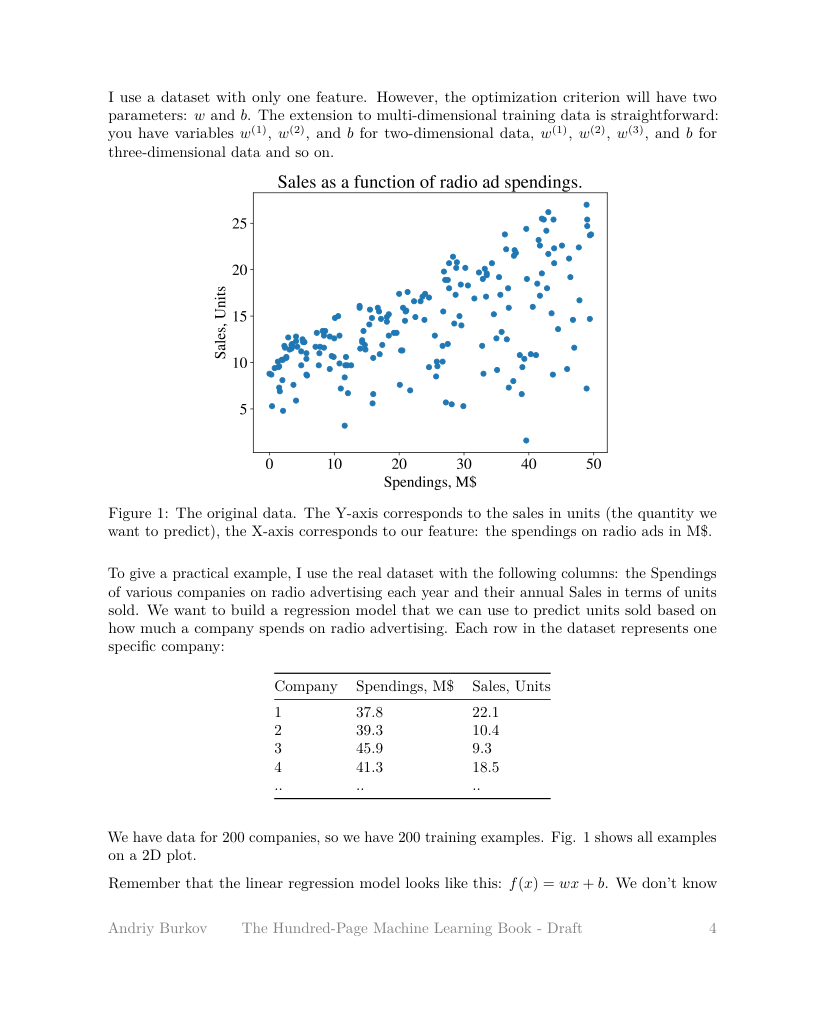

indexed text (lead-in prose, then the flattened cells), verbatim:
on radio ads in M$. To give a practical example, I use the real dataset with the following columns: the Spendings of various companies on radio advertising each year and their annual Sales in terms of units sold. We want to build a regression model that we can use to predict units sold based on how much a company spends on radio advertising. Each row in the dataset represents one speciﬁc company:
Company | Spendings M$ , | Sales Units ,
1 | 378 . | 221 .
2 | 393 . | 104 .
3 | 459 . | 93 .
4 | 413 . | 185 .
.. | .. | ..


rows in HTML: 2, cells: 6


,( predicted) spam,not spam ( predicted)
( actual) spam not spam ( actual),23 (TP) 12 (FP),1 (FN) 556 (TN)

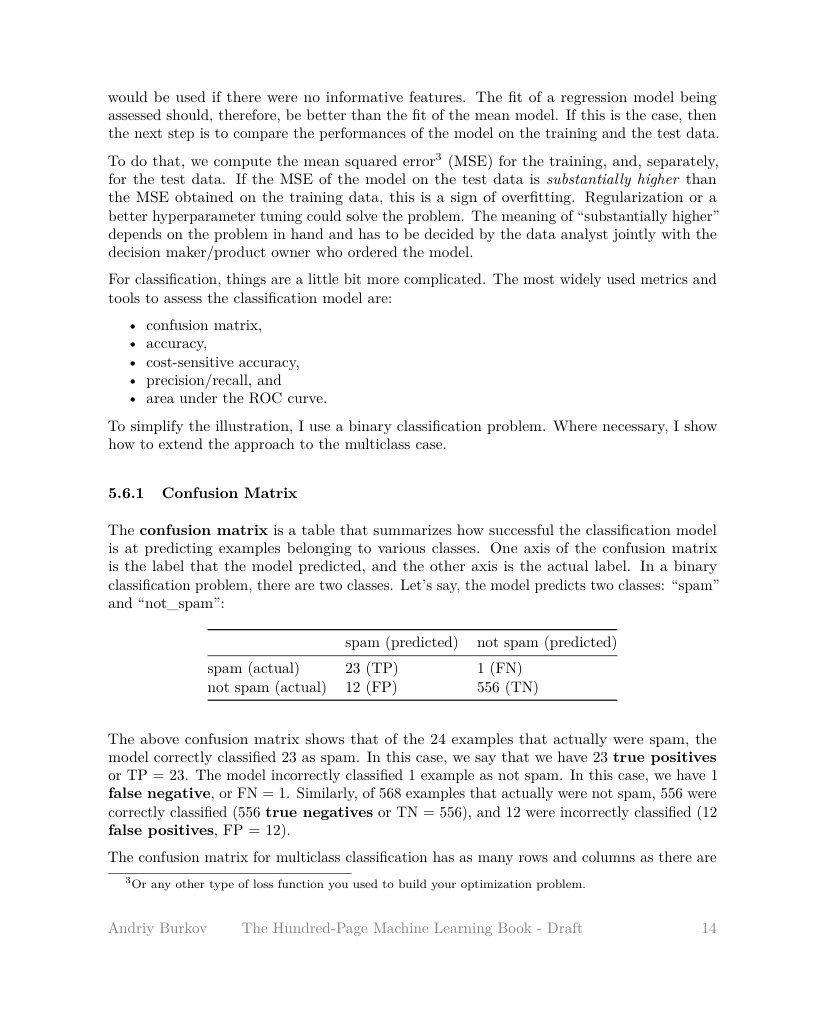

indexed text (lead-in prose, then the flattened cells), verbatim:
6.1 Confusion Matrix The confusion matrix is a table that summarizes how successful the classiﬁcation model is at predicting examples belonging to various classes. One axis of the confusion matrix is the label that the model predicted, and the other axis is the actual label. In a binary classiﬁcation problem, there are two classes. Let’s say, the model predicts two classes: “spam” and “not_spam”:
 | ( predicted) spam | not spam ( predicted)
( actual) spam not spam ( actual) | 23 (TP) 12 (FP) | 1 (FN) 556 (TN)


rows in HTML: 7, cells: 21


Fake Class,Real Class 1,Real Class 2
1,photo,portrait
2,photo,paysage
3,photo,other
4,painting,portrait
5,painting,paysage
6,painting,other

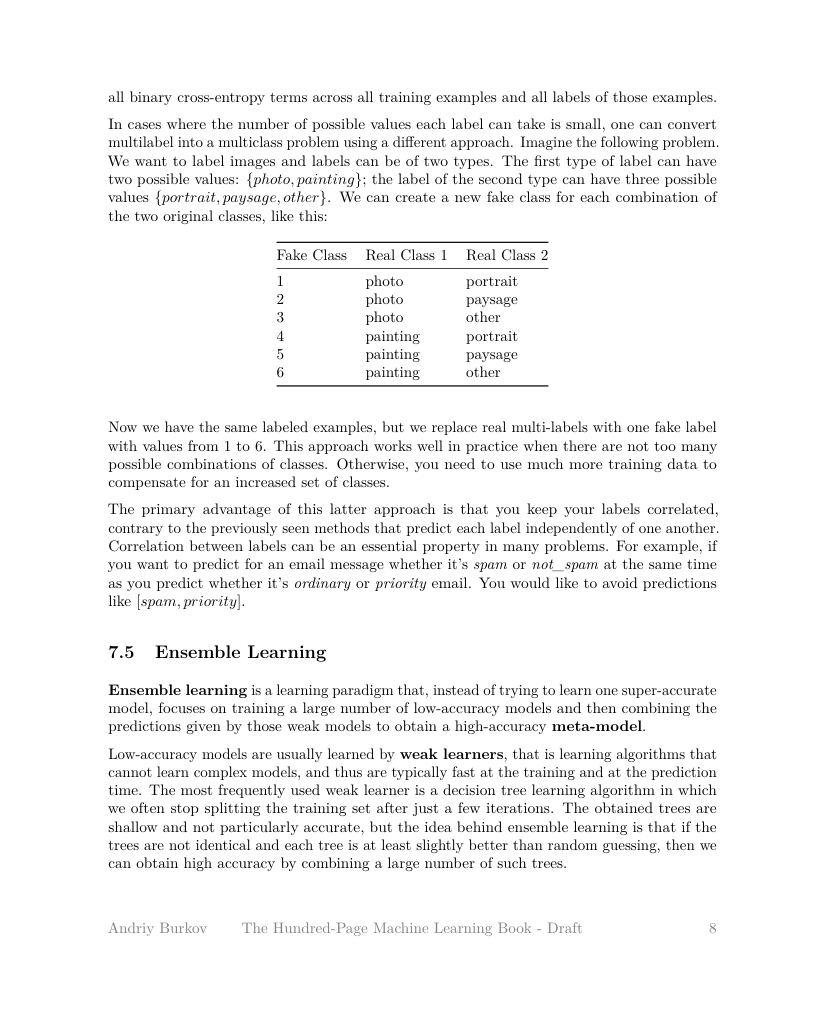

indexed text (lead-in prose, then the flattened cells), verbatim:
tilabel into a multiclass problem using a diﬀerent approach. Imagine the following problem. We want to label images and labels can be of two types. The ﬁrst type of label can have two possible values: {photo, painting}; the label of the second type can have three possible values {portrait, paysage, other}. We can create a new fake class for each combination of the two original classes, like this:
Fake Class | Real Class 1 | Real Class 2
1 | photo | portrait
2 | photo | paysage
3 | photo | other
4 | painting | portrait
5 | painting | paysage
6 | painting | other


rows in HTML: 9, cells: 261


,Ed x1,,user Al Zak x2 x3,,,,... ...,It x21,,Up x22,movie Jaws x23,,Her x24,,...,It x40,,ratedmovies Up Jaws Her x41 x42 x43,,,,,...,x99,x100,,y,
(1) x,1,,0,,0,,...,1,,0,0,,0,,...,02 .,,08 .,,04 .,0,,...,03 .,08 .,,1,(1) y
(2) x,1,,0,,0,,...,0,,1,0,,0,,...,02 .,,08 .,,04 .,0,,...,03 .,08 .,,3,(2) y
(3) x,1,,0,,0,,...,0,,0,1,,0,,...,02 .,,08 .,,04 .,07 .,,...,03 .,08 .,,2,(3) y
(4) x,0,,1,,0,,...,0,,0,1,,0,,...,0,,0,,07 .,01 .,,...,035 .,078 .,,3,(4) y
(5) x,0,,1,,0,,...,0,,0,0,,1,,...,0,,0,,07 .,01 .,,...,035 .,078 .,,1,(5) y
(6) x,0,,0,,1,,...,1,,0,0,,0,,...,08 .,,0,,0,06 .,,...,05 .,077 .,,4,(6) y
...,...,,...,,...,,...,...,,...,...,,...,,...,...,,...,,...,...,,...,...,...,,...,...
(D) x,0,,0,,0,,...,0,,0,1,,0,,...,0,,0,,1,0,,...,095 .,085 .,,5,(D) y

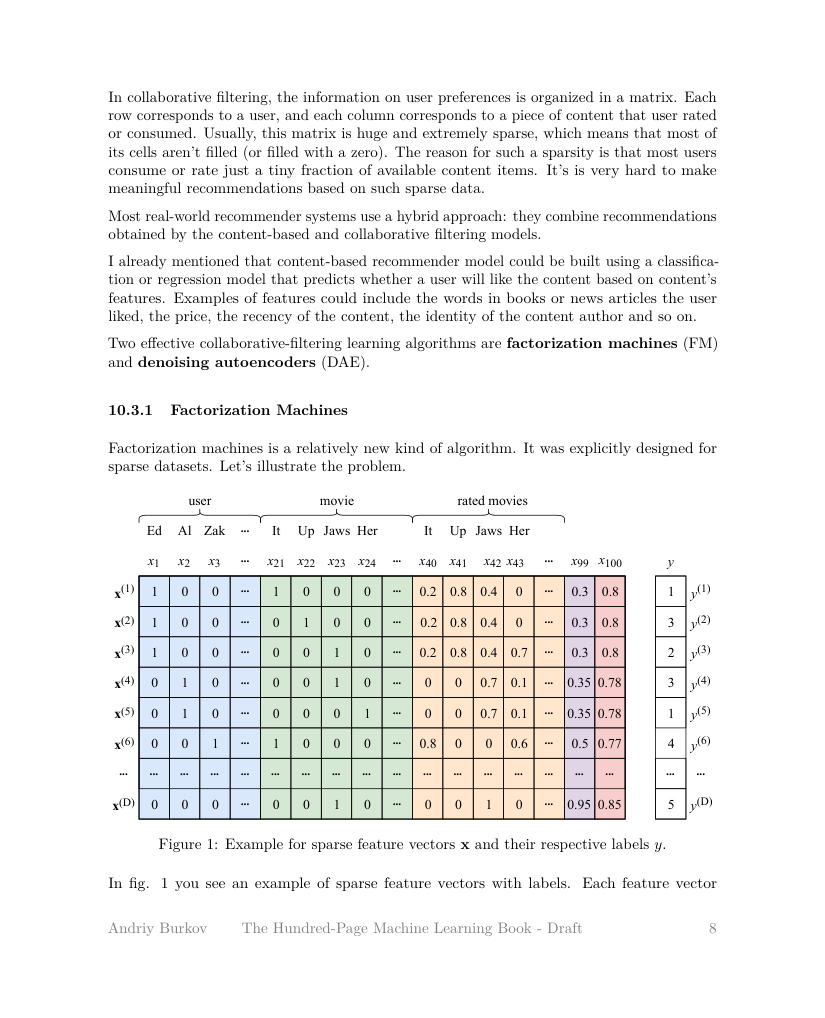

indexed text (lead-in prose, then the flattened cells), verbatim:
ticles the user liked, the price, the recency of the content, the identity of the content author and so on. Two eﬀective collaborative-ﬁltering learning algorithms are factorization machines (FM) and denoising autoencoders (DAE). 10.3.1 Factorization Machines Factorization machines is a relatively new kind of algorithm. It was explicitly designed for sparse datasets. Let’s illustrate the problem.
 | Ed x1 |  | user Al Zak x2 x3 |  |  |  | ... ... | It x21 |  | Up x22 | movie Jaws x23 |  | Her x24 |  | ... | It x40 |  | ratedmovies Up Jaws Her x41 x42 x43 |  |  |  |  | ... | x99 | x100 |  | y | 
(1) x | 1 |  | 0 |  | 0 |  | ... | 1 |  | 0 | 0 |  | 0 |  | ... | 02 . |  | 08 . |  | 04 . | 0 |  | ... | 03 . | 08 . |  | 1 | (1) y
(2) x | 1 |  | 0 |  | 0 |  | ... | 0 |  | 1 | 0 |  | 0 |  | ... | 02 . |  | 08 . |  | 04 . | 0 |  | ... | 03 . | 08 . |  | 3 | (2) y
(3) x | 1 |  | 0 |  | 0 |  | ...


In [8]:
for index in range(len(tables)):
    show_table(index)
    print("=" * 78)

## E. Extracted figure gallery

Raster images (by xref) and vector drawings (by bounding box), both rendered with `figure_image_bytes()`.

Figure index : 0
Page         : 1
Method       : raster_xref
MIME type    : image/png
Image hash   : 7dbc8222e308fbdc
XRef         : 2548
Caption      : figure on page 1 of The Hundred Page Machine Learning BOOK.pdf
Gemini summary: (not written yet - section G)


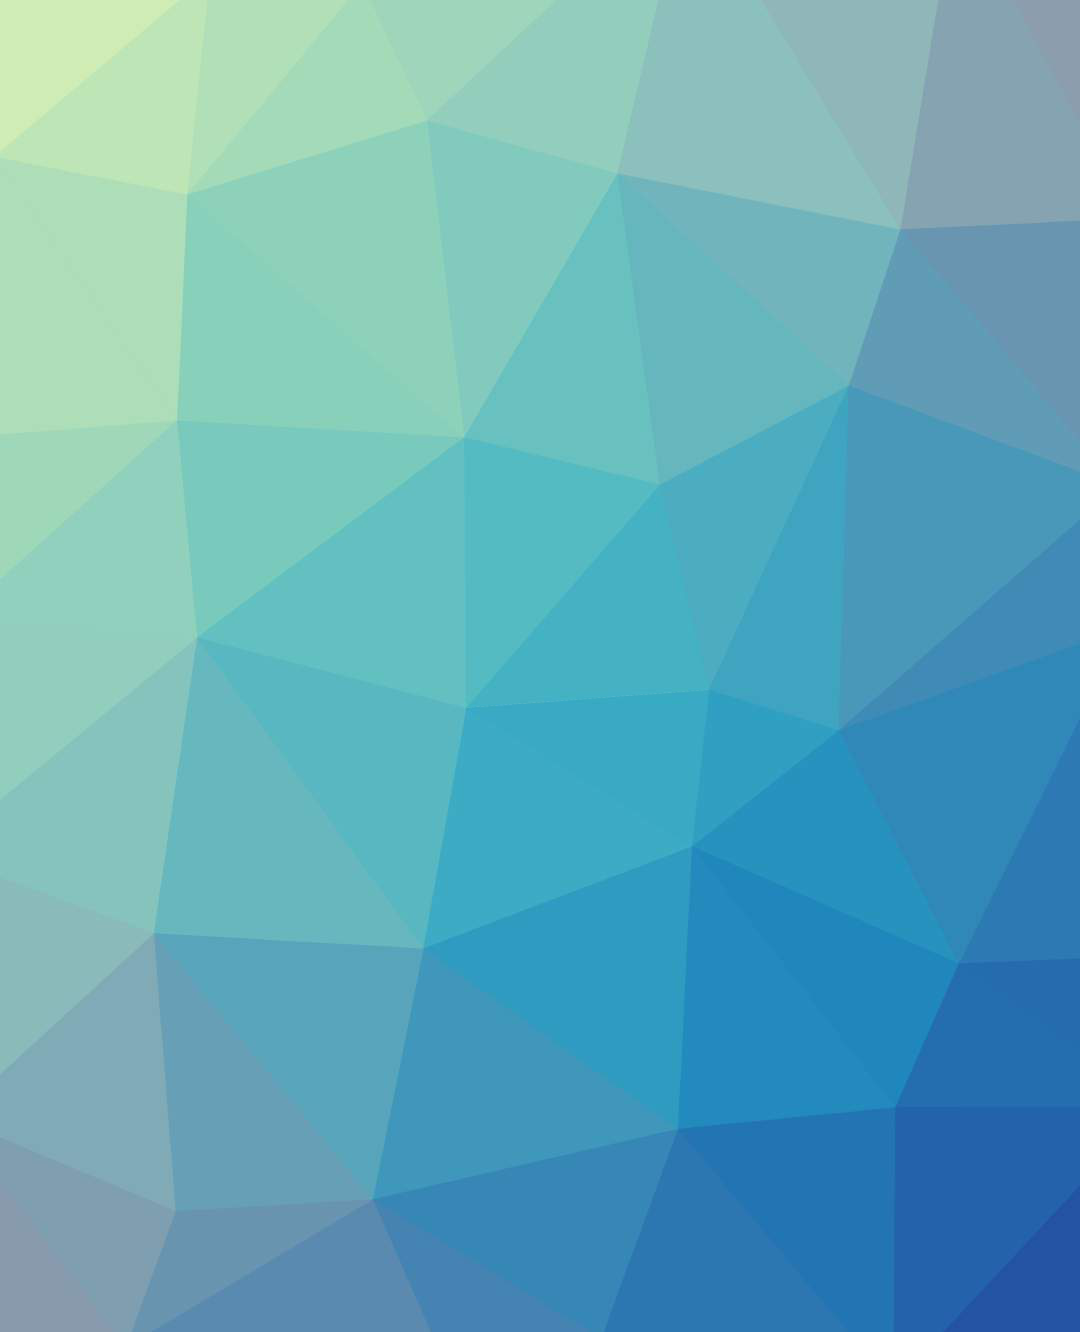

----------------------------------------------------------------------
Figure index : 1
Page         : 4
Method       : vector_drawing
MIME type    : image/png
Image hash   : e98556ecd13581ba
Bounding box : [207.47999572753906, 146.20860290527344, 332.5195007324219, 281.23101806640625]
Caption      : h your phone, you will get a link to a page on the book’s companion wiki theMLbook.com with additional materials: recommended reads, videos, Q&As, code snippets, tutorials, and other bonuses. The book’s wiki is continuously updated with contributions from the book’s author himself as well as volunte
Gemini summary: (not written yet - section G)


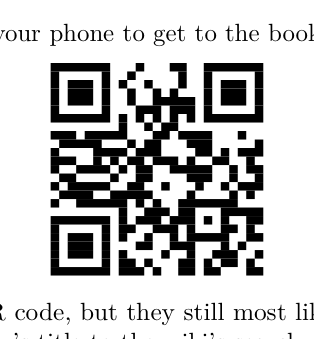

----------------------------------------------------------------------
Figure index : 2
Page         : 5
Method       : raster_xref
MIME type    : image/png
Image hash   : 7dbc8222e308fbdc
XRef         : 1949
Caption      : figure on page 5 of The Hundred Page Machine Learning BOOK.pdf
Gemini summary: (not written yet - section G)


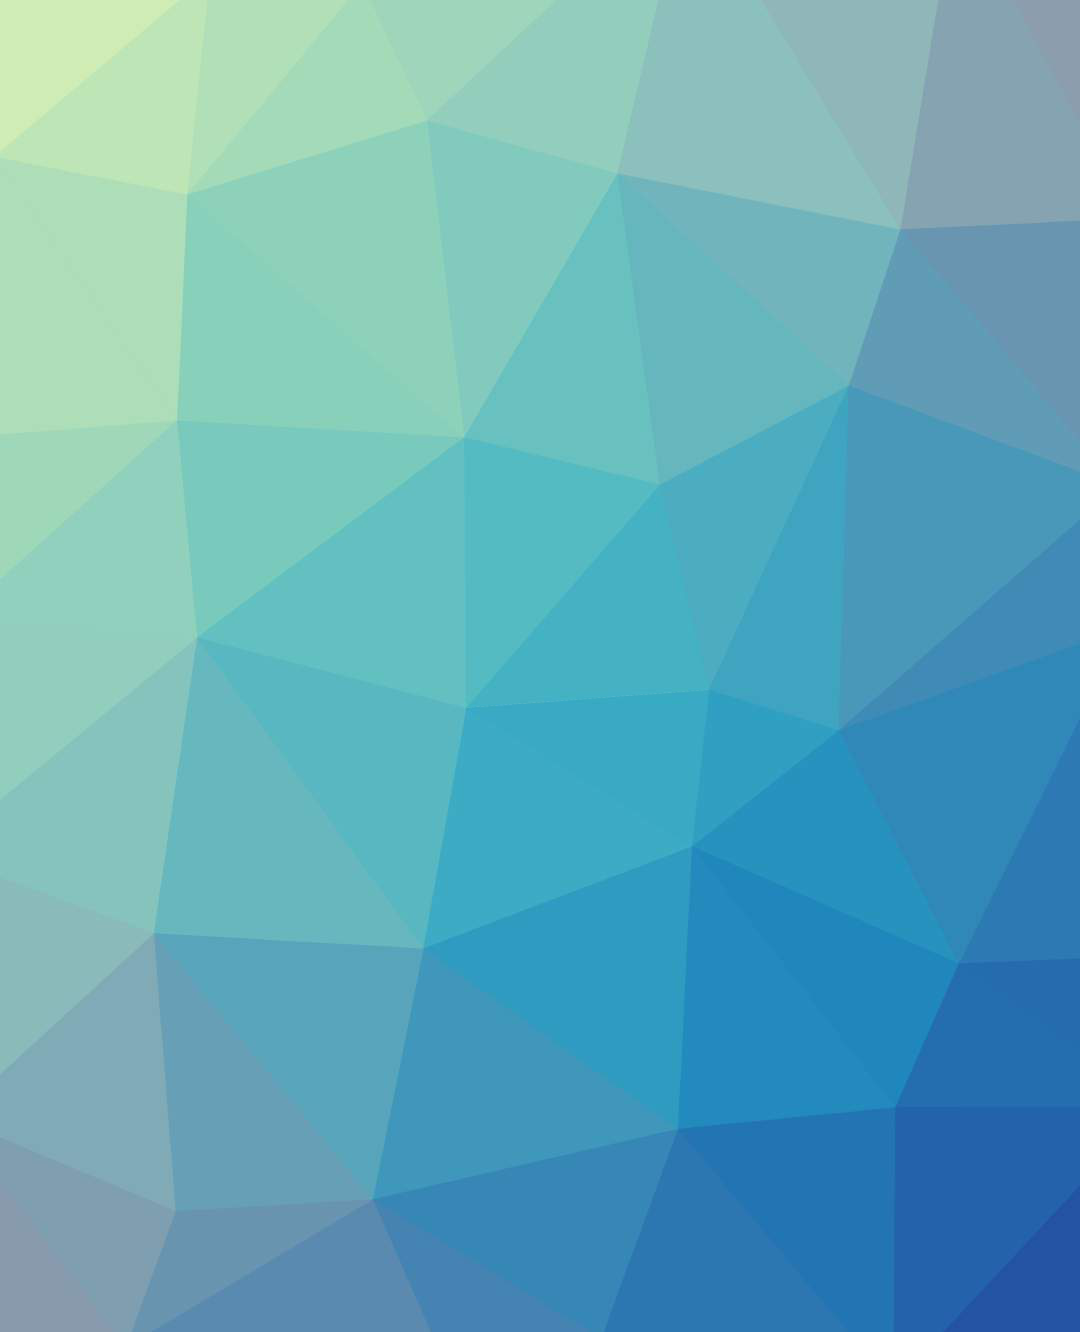

----------------------------------------------------------------------
Figure index : 3
Page         : 8
Method       : vector_drawing
MIME type    : image/png
Image hash   : 00eeb0442ead6a95
Bounding box : [50.883201599121094, 407.1676330566406, 175.9058074951172, 542.20703125]
Caption      : diﬀerent rewards and could also move the machine to another state of the environment. The goal of a reinforcement learning algorithm is to learn a policy. A policy is a function f (similar to the model in supervised learning) that takes the feature vector of a state as input and outputs an optimal a
Gemini summary: (not written yet - section G)


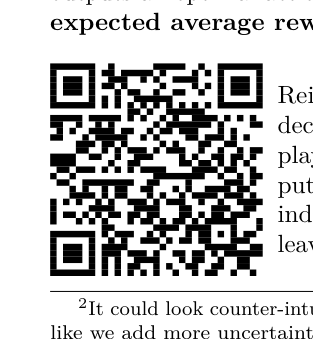

----------------------------------------------------------------------
Figure index : 4
Page         : 11
Method       : vector_drawing
MIME type    : image/png
Image hash   : 5ef2d92933e24af1
Bounding box : [120.56399536132812, 31.6910400390625, 419.4440002441406, 334.7350158691406]
Caption      : We would also prefer that the hyperplane separates positive examples from negative ones with the largest margin. The margin is the distance between the closest examples of two classes, as deﬁned by the decision boundary. A large margin contributes to a better generalization, that is how well the mod
Gemini summary: (not written yet - section G)


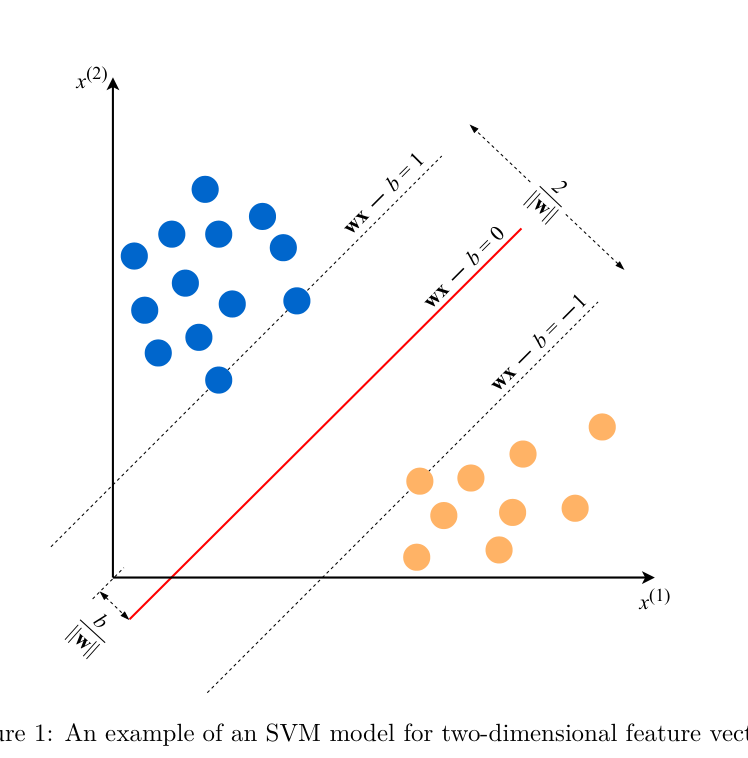

----------------------------------------------------------------------
Figure index : 5
Page         : 13
Method       : vector_drawing
MIME type    : image/png
Image hash   : a9612f4bb73415a8
Bounding box : [50.883201599121094, 33.73968505859375, 175.9058074951172, 168.779052734375]
Caption      : Andriy Burkov The Hundred-Page Machine Learning Book - Draft 9
Gemini summary: (not written yet - section G)


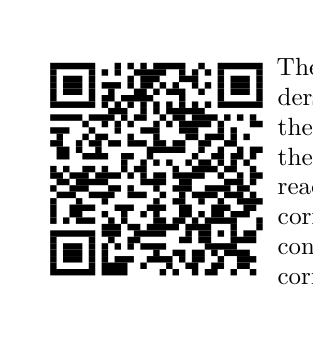

----------------------------------------------------------------------
92 further figures are available.
1 figure records found on page 69.

Figure index : 36
Page         : 69
Method       : vector_drawing
MIME type    : image/png
Image hash   : 352f142f62d6e633
Bounding box : [70.78099822998047, 31.6920166015625, 469.2340087890625, 435.9720458984375]
Caption      : Look at the illustration in Figure 3. It’s easy to see that if the threshold is 0, all our predictions will be positive, so both TPR and FPR will be 1 (the upper right corner). On the other hand, if the threshold is 1, then no positive prediction will be made, both TPR and FPR will be 0 which corres
Gemini summary: (not written yet - section G)


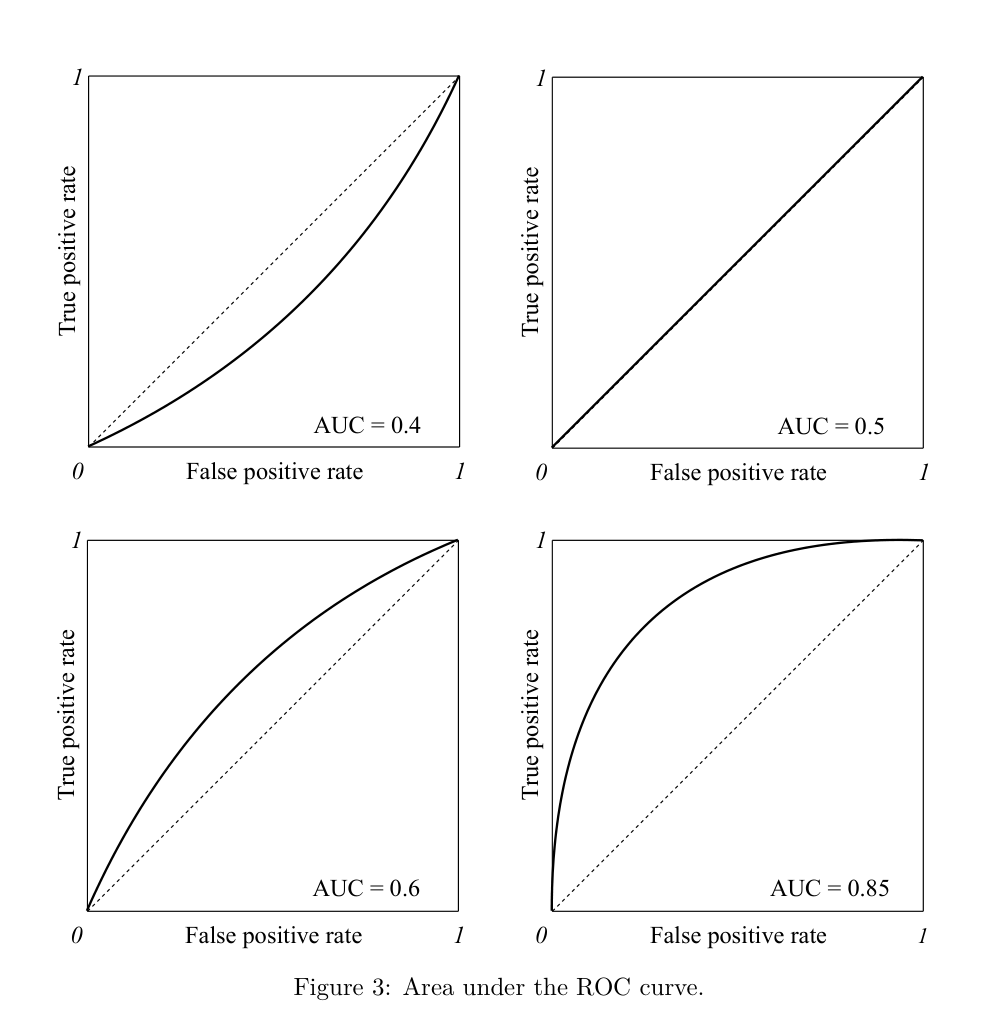

----------------------------------------------------------------------


In [9]:

import pymupdf


def show_image(index):
    """Display either a raster image or a vector-drawn figure."""
    record = images[index]

    with pymupdf.open(PDF_PATH) as document:
        image_bytes, mime_type = rp.figure_image_bytes(
            document,
            record,
        )

    method = record.get("extraction_method", "raster_xref")

    print(f"Figure index : {index}")
    print(f"Page         : {record.get('page_number')}")
    print(f"Method       : {method}")
    print(f"MIME type    : {mime_type}")
    print(f"Image hash   : {record.get('image_hash', '')[:16]}")

    if record.get("bbox"):
        print(f"Bounding box : {record['bbox']}")

    if record.get("xref") is not None:
        print(f"XRef         : {record['xref']}")

    print(f"Caption      : {record.get('caption', '')[:300]}")

    summary = record.get("summary")
    print(
        f"Gemini summary: "
        f"{(summary or '(not written yet - section G)')[:300]}"
    )

    display(ShowImage(data=image_bytes))


def show_images_on_page(page_number):
    """Display every extracted raster/vector figure from one PDF page."""
    indexes = [
        i for i, image in enumerate(images)
        if image.get("page_number") == page_number
    ]

    if not indexes:
        print(f"No raster images or vector drawings found on page {page_number}.")
        return

    print(f"{len(indexes)} figure records found on page {page_number}.\n")

    for index in indexes:
        show_image(index)
        print("-" * 70)


display(HTML("<h4>Extracted raster images and vector drawings</h4>"))

if not images:
    print("No figures were extracted.")
else:
    for i in range(min(6, len(images))):
        show_image(i)
        print("-" * 70)

    if len(images) > 6:
        print(f"{len(images) - 6} further figures are available.")

# Specifically inspect the ROC plots.
show_images_on_page(DRAWING_REVIEW_PAGE)


page 1


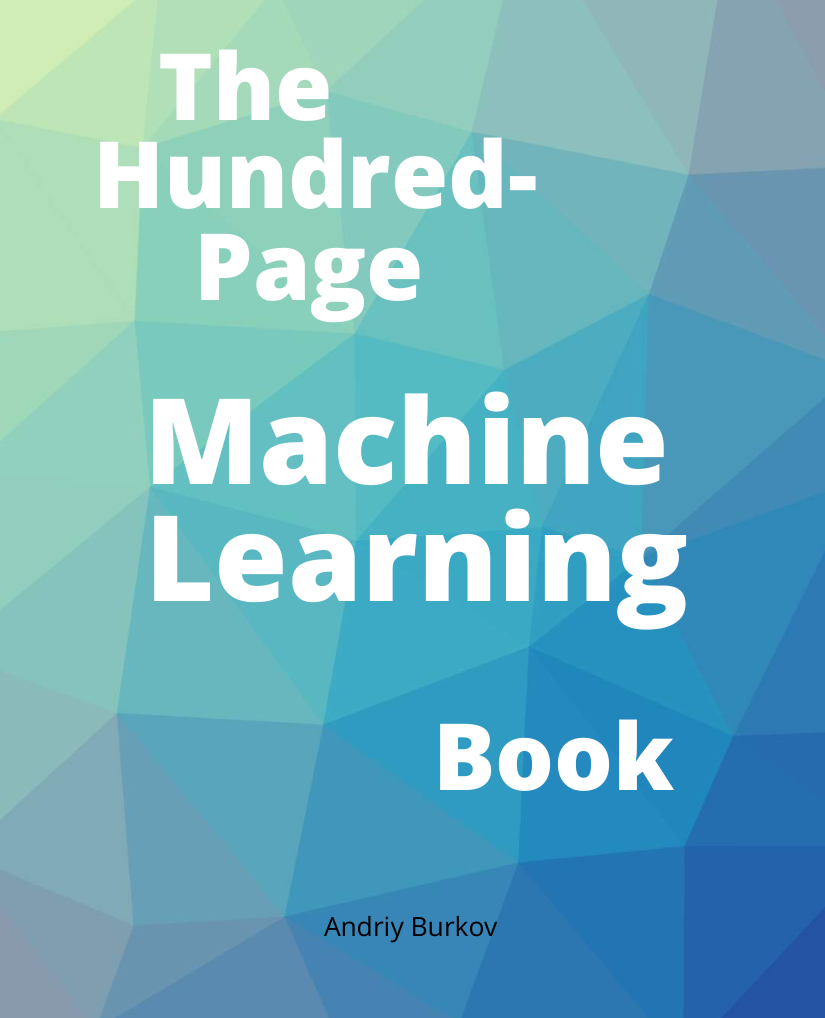

page 4


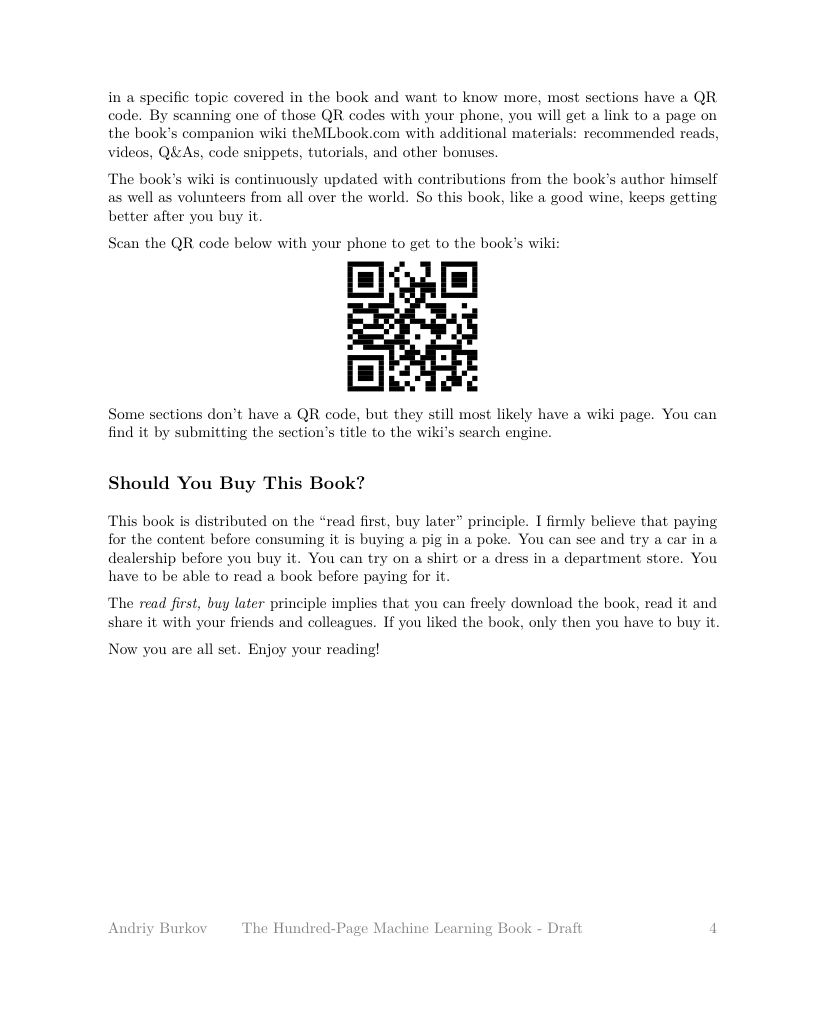

page 5


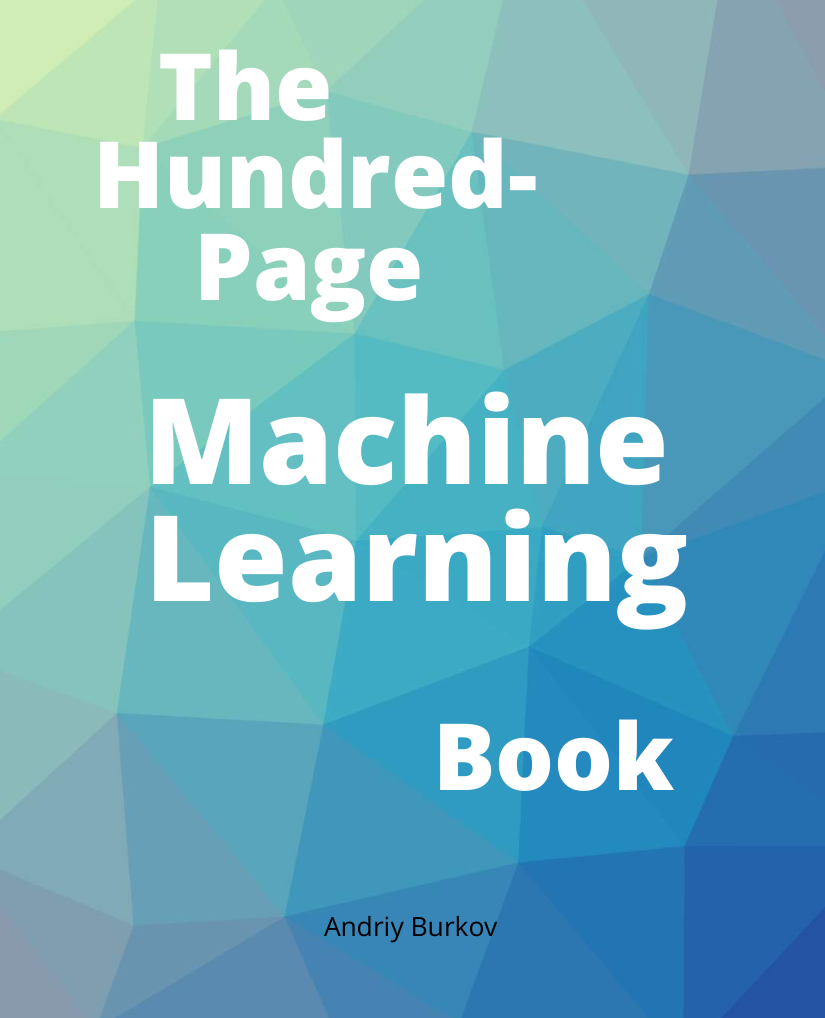

In [10]:
# Full-page renders, for comparison only. These are NOT indexed and are never
# sent to a model - they exist so you can see where each figure came from.
display(HTML("<h4>Original PDF pages &mdash; context only, never indexed</h4>"))
figure_pages = sorted({im.get("page_number") for im in images if im.get("page_number")})
for page in figure_pages[:3]:
    print(f"page {page}")
    rendered = render_page(page)
    if rendered is not None:
        display(ShowImage(data=rendered))

## F. Extraction quality review gate

Check sections C-E before enabling model calls: a bad extraction costs a re-index and a Gemini call per figure.

In [11]:
print(f"RUN_MODEL_CALLS            = {RUN_MODEL_CALLS}")
print(f"EXTRACTION_REVIEW_APPROVED = {EXTRACTION_REVIEW_APPROVED}")
print()
if MODELS_ENABLED:
    print(f"Sections G, H and I will call Gemini ({rp.ANSWER_MODEL}).")
    print(f"Budget for a full pass: 1 (section G) + {len(images)} figures "
          f"(section H) + 2 per question (section I) = {len(images) + 3} requests.")
    print("The free tier caps requests per day per model, so count these.")
else:
    print("Sections G, H and I are inert. Nothing will be sent to any API.")
    print("To enable them, set both flags to True in section A and re-run it.")

RUN_MODEL_CALLS            = True
EXTRACTION_REVIEW_APPROVED = True

Sections G, H and I will call Gemini (gemini-flash-lite-latest).
Budget for a full pass: 1 (section G) + 98 figures (section H) + 2 per question (section I) = 101 requests.
The free tier caps requests per day per model, so count these.


## G. Figure summarisation

One Gemini vision call on a sample figure, to check description quality.

In [12]:
if not MODELS_ENABLED:
    print(SKIP_NOTE)

elif not images:
    print("No figures to summarise.")

else:
    vector_sample = next(
        (
            image for image in images
            if image.get("extraction_method") == "vector_drawing"
        ),
        None,
    )

    sample_record = vector_sample if vector_sample is not None else images[0]
    sample_images = [dict(sample_record)]

    with pymupdf.open(PDF_PATH) as document:
        rp._summarise_images(document, sample_images)

    record = sample_images[0]

    print(f"Page       : {record['page_number']}")
    print(f"Method     : {record.get('extraction_method', 'raster_xref')}")
    print(f"Xref       : {record.get('xref', 'N/A')}")
    print(f"Bounding box: {record.get('bbox', 'N/A')}")
    print(f"Caption    : {record['caption'][:300]}")
    print(f"Description:\n{record.get('summary', 'No summary generated.')}")

Page       : 4
Method     : vector_drawing
Xref       : N/A
Bounding box: [207.47999572753906, 146.20860290527344, 332.5195007324219, 281.23101806640625]
Caption    : h your phone, you will get a link to a page on the book’s companion wiki theMLbook.com with additional materials: recommended reads, videos, Q&As, code snippets, tutorials, and other bonuses. The book’s wiki is continuously updated with contributions from the book’s author himself as well as volunte
Description:
The image contains a QR code positioned centrally between two lines of text. The text above the QR code reads: "vour phone to get to the boo". The text below the QR code reads: "R code, but they still most lik". The QR code itself is a square matrix composed of black and white square modules, featuring three distinct square alignment patterns located at the top-left, top-right, and bottom-left corners. There are no labeled boxes, axes, arrows, or legend entries inside the image.


In [13]:
if not MODELS_ENABLED or not images:
    print(SKIP_NOTE if not MODELS_ENABLED else "no figures to record")
else:
    # The parent record and the deterministic id for one of each content type,
    # before anything is stored.
    sample = rp.plan_records(
        texts[:1], tables[:1], sample_images, source_id=PDF_PATH.name
    )
    parents = rp.collect_records(sample, source=PDF_PATH.name)

    for record, parent in zip(sample, parents):
        print(f"content_type     : {parent.metadata.get(rp.CONTENT_TYPE_KEY)}")
        print(f"page             : {parent.metadata.get('page_number')}")
        print(f"locator          : {record['locator']}")
        print(f"id               : {record['id'][:16]}...")
        # Parent and child carry the same text: nothing stands between the
        # record and the index, so what you read is what gets embedded.
        print(f"embedded text    : {parent.page_content[:200]}")
        print()

content_type     : text
page             : 1
locator          : The Hundred Page Machine Learning BOOK.pdf|text|p1|#0
id               : f27f9c5f4fbe895b...
embedded text    : The
Hundred-
Page
Machine
Learning
Book
Andriy Burkov

content_type     : table
page             : 46
locator          : The Hundred Page Machine Learning BOOK.pdf|table|p46|#0
id               : e9f4550f26b74c6d...
embedded text    : on radio ads in M$. To give a practical example, I use the real dataset with the following columns: the Spendings of various companies on radio advertising each year and their annual Sales in terms of

content_type     : image
page             : 4
locator          : The Hundred Page Machine Learning BOOK.pdf|image|p4|#0
id               : c739bcab6e705ee0...
embedded text    : The image contains a QR code positioned centrally between two lines of text. The text above the QR code reads: "vour phone to get to the boo". The text below the QR code reads: "R code, but they still



## H. Persistent indexing and retrieval

Incremental ingestion into Chroma + SQLite: an unchanged PDF is skipped, and only changed records are re-embedded.

In [14]:
if not MODELS_ENABLED:
    print(SKIP_NOTE)
else:
    if retriever is None:
        retriever = rp.build_retriever()
    elif not isinstance(retriever.docstore, rp.SQLiteStore):
        # Section A reloads rag_pipeline, so a retriever kept from before the reload
        # holds a docstore of the old SQLiteStore class. Reopen the same SQLite file
        # with the current class; the Chroma vectorstore and its client are kept.
        stale = retriever.docstore
        retriever.docstore = rp.SQLiteStore(getattr(stale, "path", rp.STATE_DB))

    report = None  # a failed run must not leave the previous report looking current
    report = rp.ingest_pdf(PDF_PATH, retriever)
    print(f"source               : {report.source_id}")
    print(f"newly indexed        : {report.indexed}")
    print(f"reused unchanged     : {report.reused}")
    print(f"deleted (stale/gone) : {report.deleted}")
    print(f"orphans reconciled   : {report.orphans_removed}")
    print(f"source skipped whole : {report.skipped}")

d:\MultimodalRAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4248.84it/s]


source               : The Hundred Page Machine Learning BOOK.pdf
newly indexed        : 487
reused unchanged     : 0
deleted (stale/gone) : 0
orphans reconciled   : 0
source skipped whole : False


In [15]:
if report is None:
    print(SKIP_NOTE)
else:
    store = retriever.docstore
    ids = list(store.manifest(report.source_id))
    print(f"{len(ids)} parent records in {rp.STATE_DB.name}\n")

    for key in ids[:3]:
        parent = store.mget([key])[0]
        child = retriever.vectorstore.get(ids=[key], include=["documents", "metadatas"])
        child_text = (child["documents"] or [""])[0] or ""
        child_meta = (child["metadatas"] or [{}])[0] or {}
        print(f"id {key[:16]}...")
        print(f"  content_type      : {parent.metadata.get(rp.CONTENT_TYPE_KEY)}")
        print(f"  source / page     : {parent.metadata.get('source')} / "
              f"{parent.metadata.get('page_number')}")
        print(f"  child {rp.ID_KEY:<11} : {str(child_meta.get(rp.ID_KEY, ''))[:16]}...")
        print(f"  child (embedded)  : {child_text[:140]}")
        print(f"  parent (returned) : {parent.page_content[:140]}")
        print()

487 parent records in rag_state.sqlite3

id f27f9c5f4fbe895b...
  content_type      : text
  source / page     : The Hundred Page Machine Learning BOOK.pdf / 1
  child doc_id      : f27f9c5f4fbe895b...
  child (embedded)  : The
Hundred-
Page
Machine
Learning
Book
Andriy Burkov
  parent (returned) : The
Hundred-
Page
Machine
Learning
Book
Andriy Burkov

id 32125df7d019f435...
  content_type      : text
  source / page     : The Hundred Page Machine Learning BOOK.pdf / 2
  child doc_id      : 32125df7d019f435...
  child (embedded)  : “All models are wrong, but some are useful.”
— George Box
The book is distributed on the “read ﬁrst, buy later” principle.
Andriy Burkov
The
  parent (returned) : “All models are wrong, but some are useful.”
— George Box
The book is distributed on the “read ﬁrst, buy later” principle.
Andriy Burkov
The

id 9b675e9344db4b69...
  content_type      : text
  source / page     : The Hundred Page Machine Learning BOOK.pdf / 3
  child doc_id      : 9b675e9344db4b69

In [16]:
if report is None:
    print(SKIP_NOTE)
else:
    print(f"question: {QUESTION}\n")
    for doc in retriever.invoke(QUESTION):
        meta = doc.metadata
        print(f"{str(meta.get(rp.CONTENT_TYPE_KEY)):6} "
              f"page={meta.get('page_number')} source={meta.get('source')}")
        print(f"   {doc.page_content[:160]}\n")

question: Tell me more about the roc graphs

image  page=69 source=The Hundred Page Machine Learning BOOK.pdf
   The image displays four Receiver Operating Characteristic (ROC) curve graphs arranged in a 2x2 grid, titled "Figure 3: Area under the ROC curve." Top-left graph

text   page=67 source=The Hundred Page Machine Learning BOOK.pdf
   TP, TN, FP, FN as usual and multiply the counts for FP and FN by the corresponding cost
before calculating the accuracy using eq. 5.
5.6.5
Area under the ROC Cu

text   page=69 source=The Hundred Page Machine Learning BOOK.pdf
   Usually, if our model behaves well, we obtain a good classiﬁer by selecting the value of the
threshold that gives TPR close to 1 while keeping FPR near 0.
ROC c

text   page=68 source=The Hundred Page Machine Learning BOOK.pdf
   TPR =
TP
(TP + FN) and FPR =
FP
(FP + TN).
ROC curves can only be used to assess classiﬁers that return some conﬁdence score (or a
probability) of prediction. F



## I. Answer generation

Gemini grades the retrieved blocks, then answers only from the ones it kept.

In [17]:
if report is None:
    print(SKIP_NOTE)
else:
    model = rp.chat_model()
    retrieved = rp.parse_docs(retriever.invoke(QUESTION))
    kwargs = {"context": retrieved, "question": QUESTION}

    # Call 1: the grader. Shown on its own so you can see what it threw away.
    graded = rp.grade_context(kwargs, model)
    print("CORRECTIVE RAG - retrieved, then kept")
    for bucket in retrieved:
        kept_pages = [d.metadata.get("page_number") for d in graded["context"][bucket]]
        all_pages = [d.metadata.get("page_number") for d in retrieved[bucket]]
        print(f"  {bucket:7} retrieved pages {all_pages} -> kept {kept_pages}")
    print()

    # Call 2: the answer, from what survived - or no call at all.
    answer = rp.answer_question(kwargs, model)
    print("QUESTION")
    print(f"  {QUESTION}\n")
    print("ANSWER")
    print(answer)
    if answer == rp.ABSTAIN_ANSWER:
        print("\n(the grader kept nothing, so no answer call was made)")

CORRECTIVE RAG - retrieved, then kept
  texts   retrieved pages [67, 69, 68] -> kept [67, 69, 68]
  tables  retrieved pages [] -> kept []
  images  retrieved pages [69] -> kept [69]

QUESTION
  Tell me more about the roc graphs

ANSWER
Based on the provided evidence, Receiver Operating Characteristic (ROC) curves use a combination of the true positive rate (TPR) and the false positive rate (FPR) to build up a summary picture of classification performance (*The Hundred Page Machine Learning BOOK.pdf*, p. 67). 

Regarding the ROC graphs illustrated in Figure 3 (*The Hundred Page Machine Learning BOOK.pdf*, p. 69):
* **Axes:** The X-axis represents the "False positive rate" (ranging from 0 to 1), and the Y-axis represents the "True positive rate" (ranging from 0 to 1). Each graph also features a dashed diagonal line connecting (0, 0) to (1, 1).
* **Threshold extremes:** 
  * If the threshold is 0, all predictions are positive, meaning both TPR and FPR will be 1 (corresponding to the upper

## J. Live demo - five questions

Text, text, table, figure, and a question the document cannot answer - each with its answer, top relevant chunks and the retrieved figure.

ANSWER
Based on the provided evidence, the term "machine learning" was coined by Arthur Samuel in 1959 (The Hundred Page Machine Learning BOOK.pdf, p. 3).

TOP CHUNKS (kept by the relevance grader)
[1] text | The Hundred Page Machine Learning BOOK.pdf | page 3
    straight at the screen, unless it was also trained to recognize rotation, will fail to play the game on a rotated screen. So why the name “machine learning” then? The reason, as is often the case, is marketing: Arthur Samuel, an American pioneer in the ﬁeld of computer gaming and...

No relevant figure was retrieved for this question.
------------------------------------------------------------------------------


ANSWER
Based on the provided evidence, the vanishing gradient problem occurs when the gradient becomes vanishingly small during gradient descent, which effectively prevents some parameters from changing their value and, in the worst case, may completely stop the neural network from further training (*The Hundred Page Machine Learning BOOK.pdf*, pp. 77–78). 

This happens because traditional activation functions have gradients in the range $(0, 1)$, and backpropagation computes gradients using the chain rule (*The Hundred Page Machine Learning BOOK.pdf*, p. 78). This multiplies $n$ of these small numbers together to compute the gradients of the earlier layers in an $n$-layer network, causing the gradient to decrease exponentially with $n$ and resulting in the earlier layers training very slowly, if at all (*The Hundred Page Machine Learning BOOK.pdf*, p. 78).

TOP CHUNKS (kept by the relevance grader)
[1] text | The Hundred Page Machine Learning BOOK.pdf | page 77
    biggest challenges

ANSWER
Based on the provided evidence, in the spam confusion matrix example, there are:

* **True positives (TP):** 23
* **False positives (FP):** 12
* **False negatives (FN):** 1
* **True negatives (TN):** 556

Source: *The Hundred Page Machine Learning BOOK.pdf*, page 65.

TOP CHUNKS (kept by the relevance grader)
[1] text | The Hundred Page Machine Learning BOOK.pdf | page 65
    or TP = 23. The model incorrectly classiﬁed 1 example as not spam. In this case, we have 1 false negative, or FN = 1. Similarly, of 568 examples that actually were not spam, 556 were correctly classiﬁed (556 true negatives or TN = 556), and 12 were incorrectly classiﬁed (12 false...
[2] table | The Hundred Page Machine Learning BOOK.pdf | page 65
    6.1 Confusion Matrix The confusion matrix is a table that summarizes how successful the classiﬁcation model is at predicting examples belonging to various classes. One axis of the confusion matrix is the label that the model predicted, and the other axis is the

ANSWER
Based on the provided evidence, for fewer than 100K samples (`<100K samples` connected via a green arrow labeled **YES**), the recommended classifier is **Linear SVC** (The Hundred Page Machine Learning BOOK.pdf, p. 60).

TOP CHUNKS (kept by the relevance grader)
[1] image | The Hundred Page Machine Learning BOOK.pdf | page 60
    The image is a flowchart titled "scikit-learn algorithm cheat-sheet" originating from "START". It is divided into four main colored regions: "classification" (pink/red), "regression" (light blue), "clustering" (light purple), and "dimensionality reduction" (light yellow/tan). ###...

RETRIEVED FIGURE: The Hundred Page Machine Learning BOOK.pdf | page 60 | raster_xref


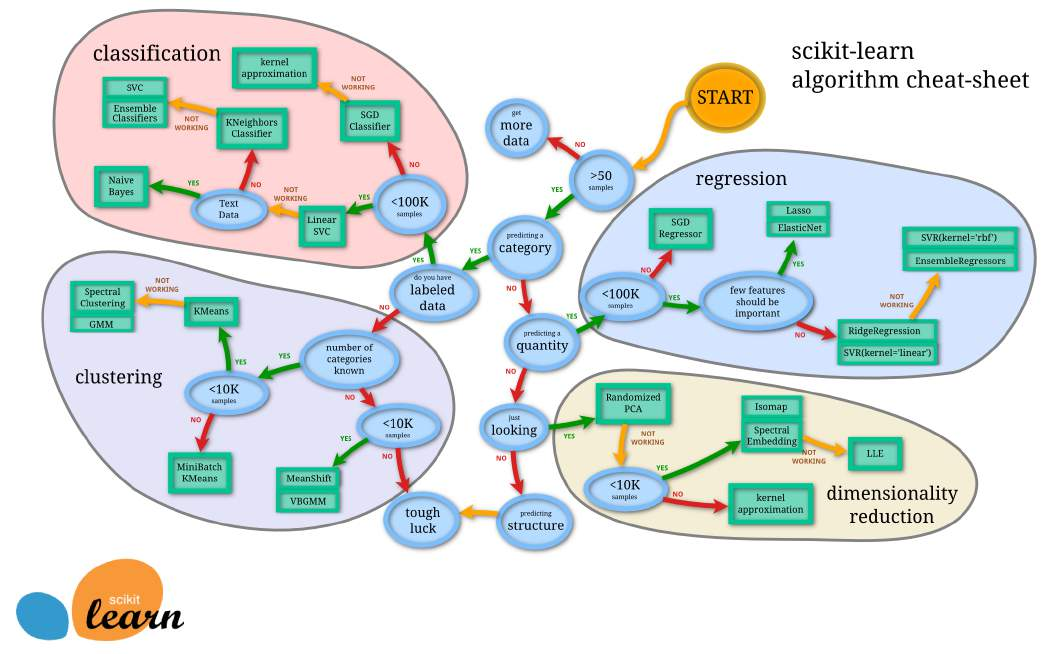

------------------------------------------------------------------------------


ANSWER
The retrieved evidence does not contain the answer to this question.

TOP CHUNKS (kept by the relevance grader)
None - the grader judged all 4 retrieved chunks irrelevant.

No relevant figure was retrieved for this question.
------------------------------------------------------------------------------


In [18]:
# Five live questions against the index section H built. Reuses `retriever` and the
# stored figure descriptions: no ingestion, no re-embedding, no figure re-summarising.
import pymupdf
from IPython.display import HTML, Image as ShowImage, display

DEMO_QUESTIONS = [
    ("text", "Who coined the term machine learning, and when?"),
    ("text", "What is the vanishing gradient problem?"),
    ("table", "In the spam confusion matrix example, how many true positives, false "
              "positives, false negatives and true negatives are there?"),
    ("figure", "In the scikit-learn algorithm cheat-sheet flowchart, which classifier "
               "is recommended for labeled data with fewer than 100K samples?"),
    # Checked absent: no "RLHF", "human feedback" or "ChatGPT" in the text of either
    # indexed PDF, nor in any stored figure description.
    ("not in the document", "What does the document say about reinforcement learning "
                            "from human feedback (RLHF), the technique used to train ChatGPT?"),
]
DEMO_CHUNKS = 2
DEMO_PREVIEW_CHARS = 280


def show_figure(doc):
    """Render a retrieved figure record - raster (xref) or vector (bbox) - from its own PDF."""
    meta = doc.metadata or {}
    pdf = PROJECT_DIR / str(meta.get("source") or "")
    if not pdf.is_file():
        print(f"(source PDF {meta.get('source')!r} not found, figure not rendered)")
        return
    try:
        with pymupdf.open(pdf) as document:
            data, _ = rp.figure_image_bytes(document, meta)
    except Exception as exc:  # e.g. a record missing its xref or bbox
        print(f"(figure not rendered: {type(exc).__name__}: {exc})")
        return
    method = meta.get("extraction_method") or "raster_xref"
    print(f"RETRIEVED FIGURE: {meta.get('source')} | page {meta.get('page_number')} | {method}")
    display(ShowImage(data=data, width=520))


if not MODELS_ENABLED:
    print(SKIP_NOTE)
else:
    if retriever is None:  # fresh kernel: reopen the persisted index, as section H does
        retriever = rp.build_retriever()
    model = rp.chat_model()

    for number, (kind, question) in enumerate(DEMO_QUESTIONS, start=1):
        display(HTML(f"<h3>Q{number} &middot; {kind}</h3><p><b>{question}</b></p>"))
        docs = retriever.invoke(question)
        kwargs = {"context": rp.parse_docs(docs), "question": question}
        try:
            # The two steps of rp.answer_question, kept apart so the grader's verdict
            # also decides which chunks and which figure are shown as relevant.
            graded = rp.grade_context(kwargs, model)
            kept = {id(d) for group in graded["context"].values() for d in group}
            answer = model.invoke(rp.build_prompt(graded)).text if kept else rp.ABSTAIN_ANSWER
            relevant, label = [d for d in docs if id(d) in kept], "kept by the relevance grader"
        except Exception as exc:  # quota or network: still show what retrieval found
            answer = f"(Gemini call failed - {type(exc).__name__}: {exc})"
            relevant, label = docs, "retrieved, not graded"

        print("ANSWER")
        print(answer.strip())

        print(f"\nTOP CHUNKS ({label})")
        for rank, doc in enumerate(relevant[:DEMO_CHUNKS], start=1):
            meta = doc.metadata or {}
            body = " ".join((doc.page_content or "").split())
            print(f"[{rank}] {meta.get(rp.CONTENT_TYPE_KEY, 'unknown')} | "
                  f"{meta.get('source', 'unknown source')} | page {meta.get('page_number', '?')}")
            print(f"    {body[:DEMO_PREVIEW_CHARS]}{'...' if len(body) > DEMO_PREVIEW_CHARS else ''}")
        if not relevant:
            print(f"None - the grader judged all {len(docs)} retrieved chunks irrelevant.")

        figures = [d for d in relevant if (d.metadata or {}).get(rp.CONTENT_TYPE_KEY) == "image"]
        if figures:
            print()
            show_figure(figures[0])
        else:
            print("\nNo relevant figure was retrieved for this question.")
        print("-" * 78)